<a href="https://colab.research.google.com/github/theanikettales/Cyber-LAB-3/blob/main/LAB3_Classifying_Cyber_Activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ENSP355: AI in Cyber Security
## Lab 3: Classifying Cyber Activity Using a Simple Neural Network

* **Institution:** K.R. Mangalam University — School of Engineering & Technology
* **Mapped Course Outcome(s):** CO4
* **Bloom's Level:** L2 - Understand / L3 - Apply
* **Focus Areas:** Dense neural networks, feature normalization, training epochs, loss/accuracy dynamics, overfitting diagnostics, and Decision Tree comparison
* **Platform:** Google Colab / Python

---
## Q1. CNN, RNN/LSTM and GAN Concept Matching (Marks: 5)

### Aim
To connect three deep-learning families with suitable cyber-security data and applications, and justify the model architecture used in this lab.

### Concept Matching Table
| Model Family | Suitable Data Type | Cyber-Security Application & Example |
| :--- | :--- | :--- |
| **CNN** (Convolutional Neural Network) | Images / grid-like spatial data | **Malware Image Classification**: Converting raw binary/bytecode into 2D grayscale images to identify malware variants via visual pattern recognition; packet header matrix filtering. |
| **RNN / LSTM** (Recurrent / Long Short-Term Memory) | Sequences / logs / time-series data | **Sequential Intrusion & Log Analysis**: Processing temporal sequences of authentication attempts, command histories, or NetFlow sessions to detect multi-step APTs and credential abuse. |
| **GAN** (Generative Adversarial Network) | Synthetic-data generation | **Adversarial Attack Simulation**: Generating realistic, synthetic malicious traffic samples and polymorphic malware variants to augment defensive training datasets and evaluate NIDS robustness. |
| **Dense Network** (Multilayer Perceptron) | Small tabular numeric feature tables | **Session Threat Classification**: Evaluating user/network behavioral metrics to classify sessions as Normal vs. Attack (as implemented in this lab). |

### Justification for Dense Network Implementation
A Dense (Fully Connected) Neural Network is used in this practical implementation because the dataset consists of four independent scalar tabular features (`failed_logins`, `login_hour`, `new_device`, `data_transfer_mb`). These structured numeric features do not exhibit local spatial hierarchies (which require CNN convolution kernels) nor sequential chronological dependencies (which require RNN recurrent loops). A dense feedforward architecture allows every input feature to interact non-linearly across hidden layers to learn predictive decision boundaries.

---
## Q2. Dataset Preparation, Split and Normalization (Marks: 5)

### Aim
To load `simple_cyber_activity.csv`, inspect class distributions, partition the dataset into 75% training and 25% testing sets with stratification, and apply feature standardization.

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('simple_cyber_activity.csv')

features = ['failed_logins', 'login_hour', 'new_device', 'data_transfer_mb']
X = df[features]
y = df['label']

print("--- Dataset Class Distribution ---")
print(y.value_counts().rename({0: 'Normal (0)', 1: 'Attack (1)'}))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n--- Split Dimensions ---")
print('Training shape:', X_train_scaled.shape)
print('Testing shape:', X_test_scaled.shape)

--- Dataset Class Distribution ---
label
Normal (0)    75
Attack (1)    25
Name: count, dtype: int64

--- Split Dimensions ---
Training shape: (75, 4)
Testing shape: (25, 4)


### Points Recorded for Lab File (Q2)
* **Dataset Class Counts:**
  * Normal (0): 75 instances (75.0%)
  * Attack (1): 25 instances (25.0%)
  * Total Records: 100 instances
* **Data Split Shapes:**
  * Training Set: `(75, 4)`
  * Testing Set: `(25, 4)`
* **Explanation of Normalization:**
  * Feature standardization via `StandardScaler` centers features to zero mean and scales to unit variance ($z = \frac{x - \mu}{\sigma}$), preventing high-magnitude features like `data_transfer_mb` (ranging in hundreds of MB) from dominating low-magnitude features like `failed_logins` or binary indicators during gradient updates.

In [7]:
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.5667 - loss: 0.6852 - val_accuracy: 0.4667 - val_loss: 0.6909
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5833 - loss: 0.6743 - val_accuracy: 0.4667 - val_loss: 0.6777
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6167 - loss: 0.6641 - val_accuracy: 0.4667 - val_loss: 0.6639
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6167 - loss: 0.6539 - val_accuracy: 0.6000 - val_loss: 0.6496
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6333 - loss: 0.6429 - val_accuracy: 0.6000 - val_loss: 0.6347
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6333 - loss: 0.6306 - val_accuracy: 0.6667 - val_loss: 0.6191
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6833 - loss: 0.6182 - val_accuracy: 0.6667 - val_loss: 0.6044
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7000 - loss: 0.6063 - val_accuracy: 0.8000 - val_loss: 0.5906


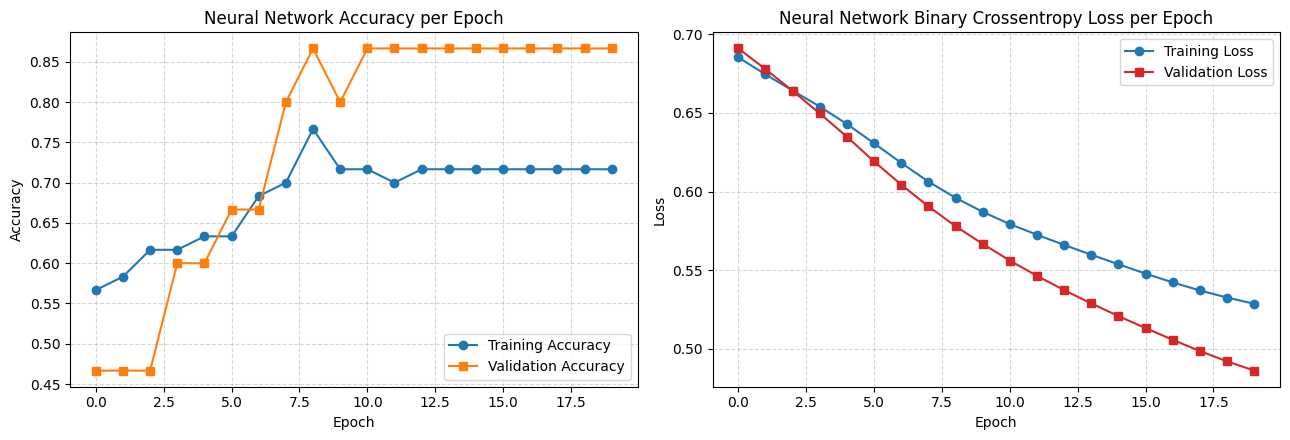

Test accuracy: 76.00%
Test loss: 0.4839


In [8]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(history.history['accuracy'], label='Training Accuracy', color='#1f77b4', marker='o')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ff7f0e', marker='s')
ax1.set_title('Neural Network Accuracy per Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(history.history['loss'], label='Training Loss', color='#1f77b4', marker='o')
ax2.plot(history.history['val_loss'], label='Validation Loss', color='#d62728', marker='s')
ax2.set_title('Neural Network Binary Crossentropy Loss per Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f'Test accuracy: {test_accuracy * 100:.2f}%')
print(f'Test loss: {test_loss:.4f}')

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

new_records = pd.DataFrame([
    {'failed_logins': 0, 'login_hour': 11, 'new_device': 0, 'data_transfer_mb': 35},
    {'failed_logins': 7, 'login_hour': 1, 'new_device': 1, 'data_transfer_mb': 250},
    {'failed_logins': 2, 'login_hour': 23, 'new_device': 1, 'data_transfer_mb': 850}
])

new_scaled = scaler.transform(new_records)
probabilities = model.predict(new_scaled, verbose=0).flatten()

new_records['nn_probability'] = probabilities.round(3)
new_records['nn_prediction'] = np.where(
    probabilities >= 0.50,
    'Attack',
    'Normal'
)

tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)
tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

new_records['tree_prediction'] = np.where(
    tree.predict(new_records[features]) == 1,
    'Attack',
    'Normal'
)

print(f'Neural-network accuracy: {test_accuracy * 100:.2f}%')
print(f'Decision-tree accuracy:   {tree_accuracy * 100:.2f}%\n')

display(new_records)

Neural-network accuracy: 76.00%
Decision-tree accuracy:   88.00%



,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.102,Normal,Normal
1,7,1,1,250,0.492,Normal,Attack
2,2,23,1,850,0.333,Normal,Attack
